# 05 · Avaliação

Medimos o erro nas casas de teste, que nenhum modelo viu, e comparamos com uma regra simples, sem Machine Learning.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.inspection import permutation_importance

DADOS = Path("..") / "data"
FIGURAS = Path("..") / "figuras"
FIGURAS.mkdir(exist_ok=True)

pacote = joblib.load(Path("..") / "models" / "modelos.joblib")
modelos, escolhido = pacote["modelos"], pacote["escolhido"]

treino = pd.read_csv(DADOS / "processed" / "treino.csv")
teste = pd.read_csv(DADOS / "processed" / "teste.csv")
X_teste = teste.drop(columns=["preco", "area_m2"])
preco_real = teste["preco"]

## 1. Erro no teste

Comparamos os três modelos com uma regra que qualquer pessoa usaria: preço = área × preço mediano por m² da freguesia (calculado com as casas de treino).

| Medida | O que diz |
|---|---|
| Erro % médio (MAPE) | Em média, quanto o modelo falha, em % do preço |
| Erro % mediano | O erro numa casa típica (metade das casas erra menos do que isto) |
| Casas com erro abaixo de 10% | Em quantas casas a estimativa fica a menos de 10% do preço |
| Erro médio em € (MAE) | Em média, quantos euros o modelo falha |
| RMSE | Também em euros, mas eleva os erros ao quadrado antes da média, por isso castiga mais os erros grandes. Se for bem maior do que o MAE, há algumas casas com erros grandes. |

In [2]:
m2_freguesia = (treino["preco"] / treino["area_m2"]).groupby(treino["freguesia"]).median()
previsoes = {"Regra simples": teste["area_m2"] * teste["freguesia"].map(m2_freguesia)}
for nome, modelo in modelos.items():
    previsoes[nome] = modelo.predict(X_teste)

linhas = []
for nome, previsto in previsoes.items():
    erro_pct = abs(previsto - preco_real) / preco_real * 100   # erro de cada casa, em %
    linhas.append({"modelo": nome,
                   "erro % médio": erro_pct.mean(),
                   "erro % mediano": erro_pct.median(),
                   "casas com erro abaixo de 10%": (erro_pct < 10).mean() * 100,
                   "erro médio (mil €)": abs(previsto - preco_real).mean() / 1000,
                   "RMSE (mil €)": np.sqrt(((previsto - preco_real) ** 2).mean()) / 1000})   # raiz da média dos erros ao quadrado

resultados = pd.DataFrame(linhas).set_index("modelo").sort_values("erro % médio").round(1)
resultados

,erro % médio,erro % mediano,casas com erro abaixo de 10%,erro médio (mil €),RMSE (mil €)
modelo,,,,,
Random Forest,14.4,10.3,49.2,127.0,205.8
XGBoost,14.7,11.2,47.6,129.5,206.1
Regressão Linear Múltipla,16.4,12.9,38.6,145.7,225.3
Regra simples,22.5,18.3,34.1,189.5,286.9


O que vemos:

- Os três modelos ganham com folga à regra simples (22,5% de erro médio).
- O XGBoost erra em média 14,7%, e 11,2% numa casa típica. Em 48% das casas fica a menos de 10% do preço.
- Em euros, falha em média 130 mil €. O RMSE (206 mil €) é bem maior: há algumas casas com erros grandes, que pesam muito quando os erros são elevados ao quadrado (o gráfico seguinte mostra-as).
- No teste, o Random Forest ficou ligeiramente melhor (14,4%). A escolha foi feita antes, com a validação cruzada, e não muda por uma diferença tão pequena: se escolhêssemos olhando para o teste, o teste deixava de ser uma medida honesta do erro.

## 2. Previsto vs real

Cada ponto é uma casa de teste. Em cima da linha, o modelo acertou em cheio.

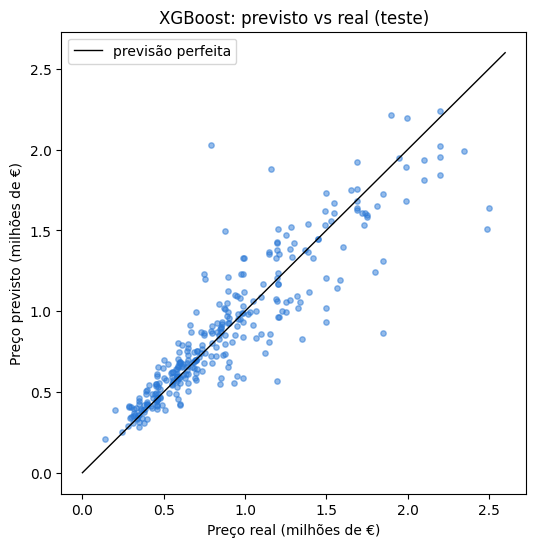

In [3]:
previsto = previsoes[escolhido]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(preco_real / 1e6, previsto / 1e6, s=15, alpha=0.5, color="#2a78d6")
ax.plot([0, 2.6], [0, 2.6], color="black", linewidth=1, label="previsão perfeita")
ax.set_title(f"{escolhido}: previsto vs real (teste)")
ax.set_xlabel("Preço real (milhões de €)")
ax.set_ylabel("Preço previsto (milhões de €)")
ax.legend()
plt.savefig(FIGURAS / "previsto_vs_real.png", dpi=120, bbox_inches="tight")
plt.show()

O que vemos: a maioria das casas fica perto da linha (76% a menos de 20% do preço real). Nas casas mais caras os pontos afastam-se mais da linha: em euros, os erros são maiores. Há alguns erros grandes, de casas que o modelo estimou muito acima do preço: deve haver coisas que não estão nos dados (obras por fazer, vista, acabamentos).

## 3. Que variáveis pesam mais?

Usamos a importância por permutação. O modelo já está treinado e não muda. Nas casas de teste, trocamos ao acaso os valores de uma só coluna entre as casas: por exemplo, cada casa fica com a área de outra casa qualquer. Os valores continuam a ser áreas normais, mas estão nas casas erradas. Depois o modelo prevê com esta tabela "estragada" e vemos quanto o erro sobe:

- se o erro sobe muito, o modelo depende muito dessa variável;
- se não muda, o modelo quase não a usa.

É como fazer um exame sem uma das informações: se a nota cai muito, essa informação era importante. Fazemos isto para cada coluna, 10 vezes, e tiramos a média.

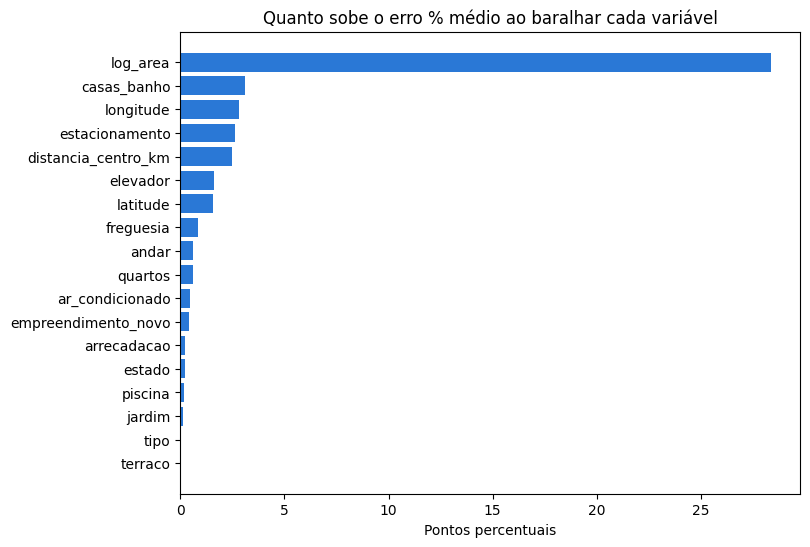

In [4]:
importancia = permutation_importance(modelos[escolhido], X_teste, preco_real, n_repeats=10,
                                     scoring="neg_mean_absolute_percentage_error", random_state=42)
subida = pd.Series(importancia.importances_mean * 100, index=X_teste.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(subida.index, subida.values, color="#2a78d6")
ax.set_title("Quanto sobe o erro % médio ao baralhar cada variável")
ax.set_xlabel("Pontos percentuais")
plt.savefig(FIGURAS / "importancia_variaveis.png", dpi=120, bbox_inches="tight")
plt.show()

O que vemos: a área é de longe a variável mais importante (baralhá-la faz o erro subir 28 pontos). Seguem-se as casas de banho, a localização (longitude, distância ao centro e latitude), o estacionamento e o elevador. A freguesia parece pouco importante porque as coordenadas já dizem onde fica a casa.

## 4. Margem de erro

Para dar uma estimativa com um intervalo, vemos onde ficou o preço real em 80% das casas de teste, em relação à estimativa.

In [5]:
racio = preco_real / previsto   # 1,10 = o preço real foi 10% acima da estimativa
margem = (racio.quantile(0.10), racio.quantile(0.90))   # entre estes dois ficam 80% das casas
print(f"Em 80% das casas, o preço real ficou entre {margem[0]:.0%} e {margem[1]:.0%} da estimativa.")

pacote["margem"] = margem
joblib.dump(pacote, Path("..") / "models" / "modelos.joblib")   # gravar a margem para o notebook 06
print("Margem gravada em models/modelos.joblib")

Em 80% das casas, o preço real ficou entre 80% e 125% da estimativa.


Margem gravada em models/modelos.joblib


## Conclusões

- O modelo escolhido, XGBoost, erra em média 14,7% e cerca de 11% numa casa típica: bem melhor do que a regra simples (22,5%).
- O que mais pesa no preço: a área, as casas de banho, a localização, o estacionamento e o elevador.
- Uma estimativa deve vir com intervalo: em 80% das casas, o preço real ficou entre 80% e 125% da estimativa.

Limitações:

- O modelo estima o preço pedido nos anúncios, não o preço de venda.
- Só serve para apartamentos em Lisboa até 2,5 milhões de €, parecidos com os dos dados (áreas de 26 a 500 m²).
- Os dados são de um só dia e não têm a idade do prédio, a vista ou os acabamentos.
- Casas invulgarmente baratas para as suas características tendem a sair estimadas a mais.